In [31]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

PROJECT_ROOT = Path.cwd().parent
MODELS = PROJECT_ROOT / "models"
RESULTS = PROJECT_ROOT / "results" / "lab6"
MODELS.mkdir(exist_ok=True)
RESULTS.mkdir(exist_ok=True)

## Part A - Tabular Q-learning in 4x4

In [13]:
rng = np.random.default_rng(42)

ROWS, COLS = 4, 4
START, GOAL, TRAP = (0, 0), (3, 3), (1, 3)

ACTIONS = [(-1, 0), (1, 0), (0, -1), (0, 1)]  # up, down, left, right
ACTION_NAMES = ["up", "down", "left", "right"]
ARROWS = {"up": (0, 1), "down": (0, -1), "left": (-1, 0), "right": (1, 0)}


def step(state, action):
    """Apply one action. Returns (next_state, reward, done)."""
    r, c = state
    dr, dc = ACTIONS[action]
    next_state = (min(max(r + dr, 0), ROWS - 1), min(max(c + dc, 0), COLS - 1))
    if next_state == GOAL:
        return next_state, 1.0, True
    if next_state == TRAP:
        return next_state, -1.0, True
    return next_state, -0.04, False

In [14]:
Q = np.zeros((ROWS, COLS, len(ACTIONS)))
alpha, gamma = 0.15, 0.95
epsilon, min_epsilon = 1.0, 0.05


def choose_action(state, explore=True):
    if explore and rng.random() < epsilon:
        return int(rng.integers(len(ACTIONS)))  # explore: random move
    return int(np.argmax(Q[state]))  # exploit: best known move


training_returns = []
for episode in range(5000):
    state, episode_return = START, 0.0
    for _ in range(100):
        action = choose_action(state)
        next_state, reward, done = step(state, action)
        episode_return += reward

        target = reward if done else reward + gamma * np.max(Q[next_state])
        Q[state][action] += alpha * (target - Q[state][action])

        state = next_state
        if done:
            break

    training_returns.append(episode_return)
    epsilon = max(min_epsilon, epsilon * 0.9985)

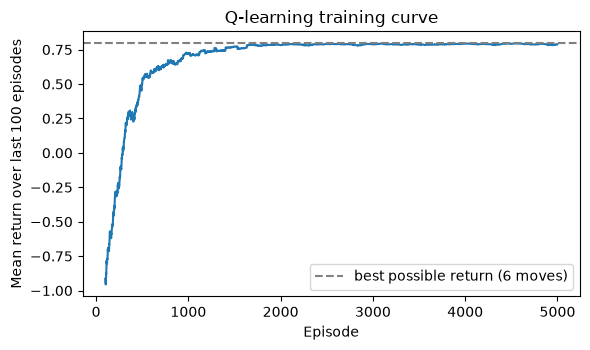

In [32]:
window = 100
moving = np.convolve(training_returns, np.ones(window) / window, mode="valid")

plt.figure(figsize=(6, 3.6))
plt.plot(np.arange(window - 1, len(training_returns)), moving)
plt.axhline(0.8, linestyle="--", color="grey", label="best possible return (6 moves)")
plt.xlabel("Episode")
plt.ylabel("Mean return over last 100 episodes")
plt.title("Q-learning training curve")
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS / "qLearning_training_curve.png", dpi=150)
plt.show()

In [33]:
successes, returns = 0, []
for _ in range(200):
    state, total = START, 0.0
    for _ in range(100):
        state, reward, done = step(state, choose_action(state, explore=False))
        total += reward
        if done:
            successes += int(state == GOAL)
            break
    returns.append(total)

print("success rate:", successes / 200)
print("mean return:", round(float(np.mean(returns)), 3))
print("learned action at start:", ACTION_NAMES[choose_action(START, explore=False)])

summary = (
    f"success rate: {successes / 200}\n"
    f"mean return: {round(float(np.mean(returns)), 3)}\n"
    f"learned action at start: {ACTION_NAMES[choose_action(START, explore=False)]}\n"
)
print(summary)
(RESULTS / "evaluation.txt").write_text(summary)

success rate: 1.0
mean return: 0.8
learned action at start: down
success rate: 1.0
mean return: 0.8
learned action at start: down



65

## Part B - The Q-table is the model

In [34]:
q_path = MODELS / "gridworld_q_table.npy"
np.save(q_path, Q)
Q_loaded = np.load(q_path)

policy = np.full((ROWS, COLS), "", dtype=object)
for r in range(ROWS):
    for c in range(COLS):
        policy[r, c] = "GOAL" if (r, c) == GOAL else "TRAP" if (r, c) == TRAP \
            else ACTION_NAMES[int(np.argmax(Q_loaded[r, c]))]

print(policy)
np.savetxt(RESULTS / "policy.txt", policy, fmt="%s")

[['down' 'down' 'down' 'left']
 ['down' 'down' 'down' 'TRAP']
 ['right' 'down' 'down' 'down']
 ['right' 'right' 'right' 'GOAL']]


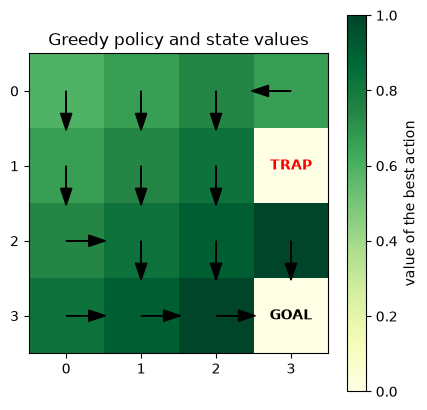

In [35]:
def plot_policy(Q_table, title, trap=TRAP, filename=None):
    values = Q_table.max(axis=2)
    plt.figure(figsize=(4.4, 4.2))
    plt.imshow(values, cmap="YlGn")
    plt.colorbar(label="value of the best action")
    for r in range(ROWS):
        for c in range(COLS):
            if (r, c) == GOAL:
                plt.text(c, r, "GOAL", ha="center", va="center", fontweight="bold")
            elif (r, c) == trap:
                plt.text(c, r, "TRAP", ha="center", va="center", color="red", fontweight="bold")
            else:
                dx, dy = ARROWS[ACTION_NAMES[int(np.argmax(Q_table[r, c]))]]
                plt.arrow(c, r, 0.3 * dx, -0.3 * dy, head_width=0.15, color="black")
    plt.xticks(range(COLS))
    plt.yticks(range(ROWS))
    plt.title(title)
    plt.tight_layout()
    if filename:
        plt.savefig(RESULTS / filename, dpi=150)
    plt.show()


plot_policy(Q_loaded, "Greedy policy and state values", filename="policy_baseline.png")

## Try it yourself question

In [22]:
def train(step_cost=-0.04, trap=TRAP, gamma=0.95, decay=0.9985,
          alpha=0.15, episodes=5000, seed=42):
    rng_local = np.random.default_rng(seed)
    Q_t = np.zeros((ROWS, COLS, len(ACTIONS)))
    eps = 1.0

    def step_fn(state, action):
        r, c = state
        dr, dc = ACTIONS[action]
        nxt = (min(max(r + dr, 0), ROWS - 1), min(max(c + dc, 0), COLS - 1))
        if nxt == GOAL:
            return nxt, 1.0, True
        if nxt == trap:
            return nxt, -1.0, True
        return nxt, step_cost, False

    for _ in range(episodes):
        state = START
        for _ in range(100):
            if rng_local.random() < eps:
                action = int(rng_local.integers(len(ACTIONS)))
            else:
                action = int(np.argmax(Q_t[state]))
            nxt, reward, done = step_fn(state, action)
            target = reward if done else reward + gamma * np.max(Q_t[nxt])
            Q_t[state][action] += alpha * (target - Q_t[state][action])
            state = nxt
            if done:
                break
        eps = max(min_epsilon, eps * decay)
    return Q_t

In [23]:
def plot_policy(Q_table, title, trap=TRAP):
    values = Q_table.max(axis=2)
    plt.figure(figsize=(4.4, 4.2))
    plt.imshow(values, cmap="YlGn")
    plt.colorbar(label="value of the best action")
    for r in range(ROWS):
        for c in range(COLS):
            if (r, c) == GOAL:
                plt.text(c, r, "GOAL", ha="center", va="center", fontweight="bold")
            elif (r, c) == trap:
                plt.text(c, r, "TRAP", ha="center", va="center", color="red", fontweight="bold")
            else:
                dx, dy = ARROWS[ACTION_NAMES[int(np.argmax(Q_table[r, c]))]]
                plt.arrow(c, r, 0.3 * dx, -0.3 * dy, head_width=0.15, color="black")
    plt.xticks(range(COLS))
    plt.yticks(range(ROWS))
    plt.title(title)
    plt.tight_layout()
    plt.show()

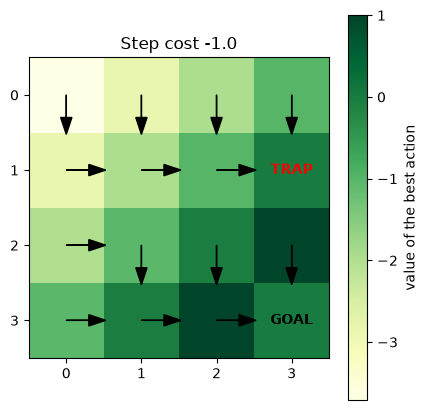

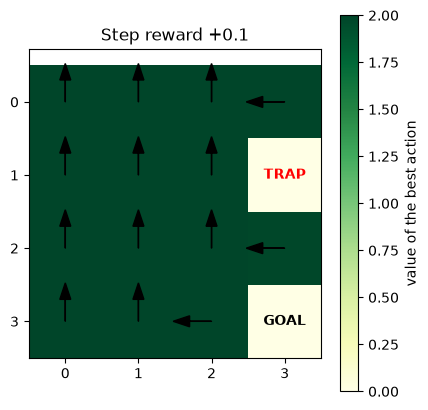

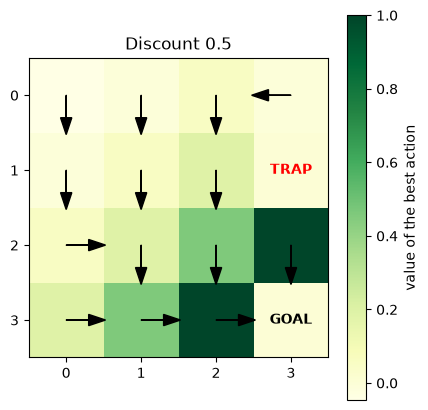

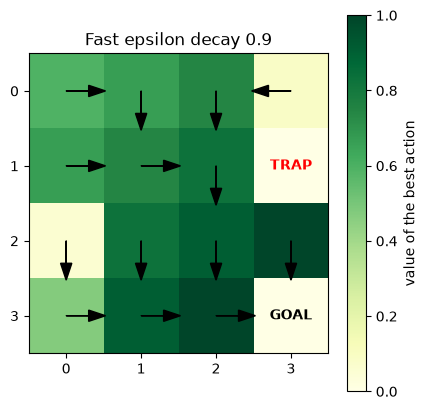

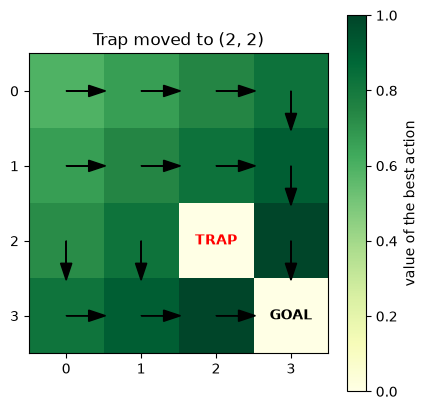

In [36]:
experiments = {
    "Step cost -1.0": dict(step_cost=-1.0),
    "Step reward +0.1": dict(step_cost=0.1),
    "Discount 0.5": dict(gamma=0.5),
    "Fast epsilon decay 0.9": dict(decay=0.9),
    "Trap moved to (2, 2)": dict(trap=(2, 2)),
}

for name, kwargs in experiments.items():
    Q_exp = train(**kwargs)
    fname = "policy_" + name.lower().replace(" ", "_").replace(",", "").replace("(", "").replace(")", "") + ".png"
    plot_policy(Q_exp, name, trap=kwargs.get("trap", TRAP), filename=fname)